In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 14 - Ageing costs and debt scenarios
European Commission / EPC 2024 Ageing Report projections (2022-2070) and a simple, transparent debt simulation. The simulation is an illustration of arithmetic, not a forecast.

pensions | Italy: {2022: np.float64(15.6), 2030: np.float64(16.6), 2040: np.float64(17.1), 2050: np.float64(15.5), 2070: np.float64(13.7)} | median of others (n=25): {2022: np.float64(9.0), 2030: np.float64(10.2), 2040: np.float64(10.4), 2050: np.float64(10.7), 2070: np.float64(10.5)}
total | Italy: {2022: np.float64(27.3), 2030: np.float64(27.6), 2040: np.float64(28.3), 2050: np.float64(27.3), 2070: np.float64(25.3)} | median of others (n=26): {2022: np.float64(20.8), 2030: np.float64(21.4), 2040: np.float64(22.8), 2050: np.float64(23.5), 2070: np.float64(24.5)}
old-age dependency | Italy: {2022: np.float64(40.8), 2030: np.float64(48.0), 2040: np.float64(60.8), 2050: np.float64(66.0), 2070: np.float64(65.5)} | median of others (n=26): {2022: np.float64(34.7), 2030: np.float64(39.7), 2040: np.float64(46.4), 2050: np.float64(51.1), 2070: np.float64(57.4)}


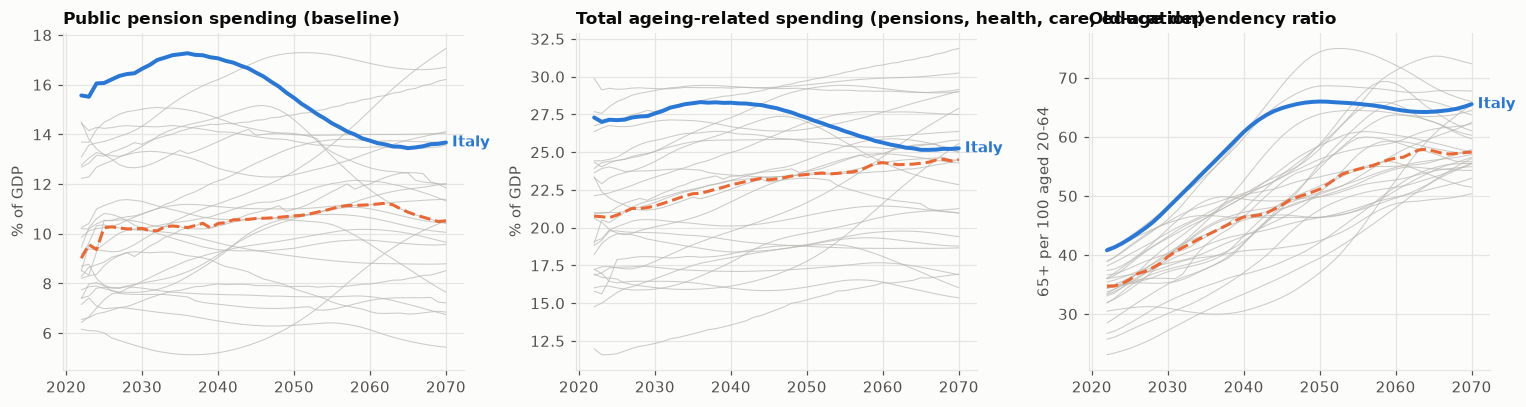

In [2]:
ar = load_ageing()
pens = ageing_series(ar, "Baseline as % of GDP", "Public pensions, gross"); tot = ageing_series(ar, "Total spending as % of GDP", "Baseline")
oad = ageing_series(ar, "Dependency ratios", "Old-age dependency ratio (3)")
def panel_lines(ax, w, title, ylabel):
    eu = [c for c in EU27_ISO3 if c in w and c != ITALY]
    for c in eu: ax.plot(w.index, w[c], color=PEER_C, lw=0.7, alpha=0.7)
    ax.plot(w.index, w[eu].median(axis=1), color=EU_C, lw=2, ls="--"); ax.plot(w.index, w[ITALY], color=ITALY_C, lw=2.6)
    ax.annotate("Italy", (w.index[-1], w[ITALY].iloc[-1]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center"); ax.set_title(title); ax.set_ylabel(ylabel)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
panel_lines(axes[0], pens, "Public pension spending (baseline)", "% of GDP"); panel_lines(axes[1], tot, "Total ageing-related spending (pensions, health, care, education)", "% of GDP"); panel_lines(axes[2], oad, "Old-age dependency ratio", "65+ per 100 aged 20-64")
fig.tight_layout(); save(fig, "14_ageing_projections")
for nm, w in [("pensions", pens), ("total", tot), ("old-age dependency", oad)]:
    eu = [c for c in EU27_ISO3 if c != ITALY and c in w]  # a few countries are missing some variables in the annex
    print(nm, "| Italy:", {y: round(w.loc[y, ITALY], 1) for y in (2022, 2030, 2040, 2050, 2070)}, "| median of others (n=%d):" % len(eu), {y: round(w.loc[y, eu].median(), 1) for y in (2022, 2030, 2040, 2050, 2070)})

In [3]:
# Sensitivity of Italian pension spending to assumptions (pp of GDP vs baseline; Ageing Report scenarios)
sec = "Public pensions, gross as % of GDP (difference from baseline)"
sens = ar[(ar.iso3 == ITALY) & (ar.section == sec) & ar.year.isin([2040, 2070])].pivot(index="variable", columns="year", values="value")
display(sens.round(2))

year,2040,2070
variable,,
Constant benefit ratio,0.00,1.54
Constant retirement age,0.89,1.16
High life expectancy (+2 years),-0.02,-0.12
Higher TFP growth (+0.2 pps),0.00,-0.44
Higher employment rate of older workers (+10 pps),-0.67,0.26
Higher migration (+33%),-0.40,-0.55
Lower TFP growth (-0.2 pps),0.19,0.62
Lower fertility (-20%),-0.01,0.64
Lower migration (-33%),0.42,0.70


2024: debt 134.3% GDP, primary balance +0.5% GDP, implicit rate 2.9% | assumptions 2025-2050: nominal growth 3.1%, interest rate 4.2%, r-g +1.1 pp


,2030,2040,2050
"primary balance stays at 2024 level, ageing costs unoffset",137.0,166.0,182.0
"primary surplus +2% GDP, ageing costs unoffset",128.0,139.0,137.0
"primary surplus +3% GDP, ageing costs unoffset",122.0,121.0,108.0
"primary surplus +2% GDP, interest rate +1 pp",136.0,164.0,181.0


Primary surplus that holds debt at 134% of GDP for r-g = 0.5/1.0/1.5/2.0 pp: [np.float64(0.7), np.float64(1.3), np.float64(2.0), np.float64(2.6)]


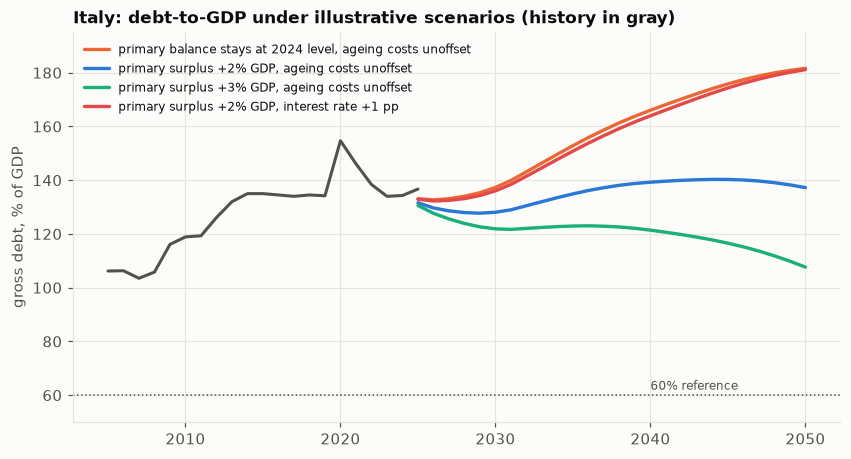

In [4]:
from cifresignificative.studies.italy_productivity.analysis.scenarios import simulate_debt, stabilising_primary_balance
bal = wide(panel, "gov_balance_pct_gdp")[ITALY]; intr = wide(panel, "gov_interest_pct_gdp")[ITALY]; debt = wide(panel, "gov_debt_pct_gdp")[ITALY]
d0 = debt.loc[2024]; pb0 = (bal + intr).loc[2024]; r0 = intr.loc[2024] / debt.loc[2023]  # both in % of GDP, so the ratio is already a fraction
real = ageing_series(ar, "Macroeconomic assumptions", "Potential GDP (growth rate)")[ITALY] / 100; infl = ageing_series(ar, "Macroeconomic assumptions", "HICP (growth rate)")[ITALY] / 100
r_ar = ageing_series(ar, "Macroeconomic assumptions", "Nominal interest rate")[ITALY] / 100; cost = tot[ITALY]
yrs = range(2025, 2051); g = np.array([(1 + real.loc[y]) * (1 + infl.loc[y]) - 1 for y in yrs])
r = np.array([r0 + (r_ar.loc[y] - r0) * min((y - 2024) / 8, 1) for y in yrs])  # implicit rate converges to the Commission's nominal interest assumption by 2032
drift = np.array([cost.loc[y] - cost.loc[2024] for y in yrs])  # extra ageing-related spending vs 2024, not offset
print(f"2024: debt {d0:.1f}% GDP, primary balance {pb0:+.1f}% GDP, implicit rate {r0*100:.1f}% | assumptions 2025-2050: nominal growth {g.mean()*100:.1f}%, interest rate {r.mean()*100:.1f}%, r-g {np.mean(r-g)*100:+.1f} pp")
scen = {"primary balance stays at 2024 level, ageing costs unoffset": simulate_debt(d0, yrs, pb0, r, g, drift), "primary surplus +2% GDP, ageing costs unoffset": simulate_debt(d0, yrs, 2.0, r, g, drift),
        "primary surplus +3% GDP, ageing costs unoffset": simulate_debt(d0, yrs, 3.0, r, g, drift), "primary surplus +2% GDP, interest rate +1 pp": simulate_debt(d0, yrs, 2.0, r + 0.01, g, drift)}
fig, ax = plt.subplots(figsize=(9, 4.6)); ax.plot(debt.index, debt.values, color=INK2, lw=2)
cols = [EU_C, ITALY_C, "#1baf7a", "#e34948"]
for (lab, sr), col in zip(scen.items(), cols): ax.plot(sr.index, sr.values, color=col, lw=2.2, label=lab)
ax.axhline(60, color=INK2, lw=1, ls=":"); ax.annotate("60% reference", (2040, 62), fontsize=8, color=INK2); ax.set_ylim(50, 195); ax.set_ylabel("gross debt, % of GDP"); ax.set_title("Italy: debt-to-GDP under illustrative scenarios (history in gray)"); ax.legend(fontsize=8, loc="upper left"); save(fig, "14_debt_scenarios")
display(pd.DataFrame({k: v.loc[[2030, 2040, 2050]] for k, v in scen.items()}).round(0).T)
print("Primary surplus that holds debt at %.0f%% of GDP for r-g = 0.5/1.0/1.5/2.0 pp:" % d0, [round(stabilising_primary_balance(d0, 0.5 / 100 + 0.03, 0.03), 1), round(stabilising_primary_balance(d0, 1 / 100 + 0.03, 0.03), 1), round(stabilising_primary_balance(d0, 1.5 / 100 + 0.03, 0.03), 1), round(stabilising_primary_balance(d0, 2 / 100 + 0.03, 0.03), 1)])

## Takeaways (EC/EPC 2024 Ageing Report baseline; illustrative simulation)
- **Italy's pension bill is high today and keeps rising for a decade.** Gross public pension spending is projected at 15.6% of GDP in 2022, 16.6% in 2030, a peak of 17.1% in 2040, then 15.5% (2050) and 13.7% (2070), against a median of 9.0%, 10.2%, 10.4%, 10.7% and 10.5% for the other members (n=25). Total ageing-related spending (pensions, health, long-term care, education) is 27.3% of GDP in 2022 and 28.3% in 2040, vs 20.8% and 22.8%.
- **Demography:** the old-age dependency ratio is projected to rise from 40.8 to 66.0 (2050) vs 34.7 to 51.1 for the median.
- **Policy sensitivities (pp of GDP, Italian baseline):** a constant retirement age instead of the legislated link to life expectancy would add 0.9 pp by 2040 and 1.2 pp by 2070; 10 pp higher employment of older workers lowers spending by 0.7 pp in 2040; lower migration adds 0.4 pp (2040) and 0.7 pp (2070).
- **Illustrative debt arithmetic** (2024 debt 134.3% of GDP, primary balance +0.5%, implicit rate 2.9% rising to the Commission's interest assumption, nominal growth 3.1%, so r-g about +1.1 pp): keeping the 2024 primary balance while ageing costs are not offset takes debt to 137% (2030), 166% (2040) and 182% (2050). A primary surplus of 2% of GDP gives 128%, 139% and 137%; 3% gives 122%, 121% and 108%. Holding debt at its current level needs a primary surplus of about 1.3% of GDP if r-g is 1.0 pp and 2.6% if it is 2.0 pp.
- The simulation ignores stock-flow adjustments, growth feedbacks from fiscal policy and changes in the interest path beyond the stated rule; use it for orders of magnitude and for the sensitivity to r-g, not as a forecast.